# TSR KPI Explorer — AV Portfolio

Exploratory analysis of the Traffic Sign Recognition evaluation output:

- `data/processed/results.parquet` — 5M frames with per-frame KPI flags (TP/TN/FP/FN/critical/poor-localization),
- `data/outputs/redash_db.sqlite` — aggregated BI report (`kpi_report` table).

Run the pipeline first: `uv run python demo_run.py`.

Definitions of all KPIs: see `docs/kpi-definition.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)

ROOT = Path("..").resolve()
FIGURES_DIR = ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {0: "NONE", 1: "STOP", 2: "YIELD", 3: "SPEED_LIMIT", 4: "OTHER"}
WEATHER_NAMES = {0: "SUNNY", 1: "RAIN", 2: "FOG"}

## 1. Dataset overview

In [2]:
df = pl.read_parquet(ROOT / "data/processed/results.parquet")
df.shape

(5000000, 12)

In [3]:
(
    df.group_by("actual_class")
    .len(name="frames")
    .sort("actual_class")
    .with_columns(
        pl.col("actual_class")
        .replace_strict(CLASS_NAMES, return_dtype=pl.Utf8)
        .alias("class_name")
    )
    .select("actual_class", "class_name", "frames")
    .with_columns((pl.col("frames") / pl.col("frames").sum()).round(4).alias("share"))
)

actual_class,class_name,frames,share
i64,str,u32,f64
0,"""NONE""",2501761,0.5004
1,"""STOP""",249672,0.0499
2,"""YIELD""",249685,0.0499
3,"""SPEED_LIMIT""",1749179,0.3498
4,"""OTHER""",249703,0.0499


## 2. Overall KPI summary

Flags already include the *effective prediction* semantics: predictions with
`confidence < 0.7` are treated as NONE (`CONFIDENCE_THRESHOLD` in
`src/av_portfolio/assets/metrics.py`).

In [4]:
totals = df.select(
    pl.col("is_true_positive").sum().alias("tp"),
    pl.col("is_true_negative").sum().alias("tn"),
    pl.col("is_false_positive").sum().alias("fp"),
    pl.col("is_false_negative").sum().alias("fn"),
    pl.col("is_critical_failure").sum().alias("critical"),
    pl.col("is_poor_localization").sum().alias("poor_localization"),
)
tp = totals["tp"].item()
fp = totals["fp"].item()
fn = totals["fn"].item()

{
    "frames": df.height,
    "tp": tp,
    "tn": totals["tn"].item(),
    "fp": fp,
    "fn": fn,
    "critical_failures": totals["critical"].item(),
    "poor_localizations": totals["poor_localization"].item(),
    "precision": round(tp / (tp + fp), 4),
    "recall": round(tp / (tp + fn), 4),
    "f1": round(2 * tp / (2 * tp + fp + fn), 4),
}

{'frames': 5000000,
 'tp': 2039361,
 'tn': 2481703,
 'fp': 34930,
 'fn': 458878,
 'critical_failures': 42611,
 'poor_localizations': 247325,
 'precision': 0.9832,
 'recall': 0.8163,
 'f1': 0.892}

## 3. Recall by sign class and weather

Recall per sign class (`actual_class != NONE`) computed directly from raw
columns, using the same effective-prediction rule.

In [5]:
CONFIDENCE_THRESHOLD = 0.7

signs = df.filter(pl.col("actual_class") != 0).with_columns(
    detected=(
        (pl.col("confidence") >= CONFIDENCE_THRESHOLD)
        & (pl.col("predicted_class") == pl.col("actual_class"))
    )
)

recall_by_class_weather = (
    signs.group_by(["actual_class", "weather"])
    .agg(pl.col("detected").mean().alias("recall"))
    .sort(["actual_class", "weather"])
)
recall_by_class_weather

actual_class,weather,recall
i64,i64,f64
1,0,0.822439
1,1,0.824771
1,2,0.175259
2,0,0.823235
2,1,0.824413
…,…,…
3,1,0.822459
3,2,0.821376
4,0,0.823356


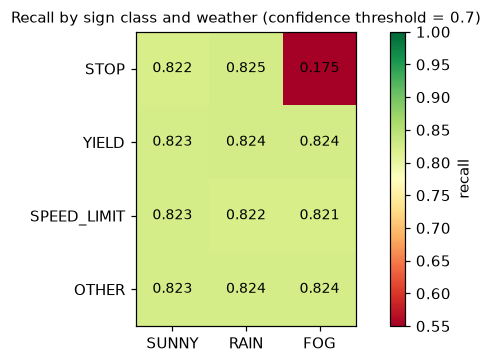

In [6]:
pivot = recall_by_class_weather.pivot(on="weather", index="actual_class", values="recall").sort(
    "actual_class"
)
matrix = pivot.drop("actual_class").to_numpy()
row_labels = [CLASS_NAMES[c] for c in pivot["actual_class"].to_list()]
col_labels = [WEATHER_NAMES[c] for c in (0, 1, 2)]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
image = ax.imshow(matrix, cmap="RdYlGn", vmin=0.55, vmax=1.0)
ax.set_xticks(range(len(col_labels)), col_labels)
ax.set_yticks(range(len(row_labels)), row_labels)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="recall")
ax.set_title("Recall by sign class and weather (confidence threshold = 0.7)", fontsize=10)
ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_recall_by_class_weather.png")
plt.show()

## 4. Localization quality

Class-correct detections with bounding-box IoU below 0.7 are flagged as
*poor localization* (`is_poor_localization`). How well are matched signs boxed?

In [7]:
tps = df.filter(pl.col("is_true_positive") == 1)

localization = (
    tps.group_by("weather")
    .agg(
        pl.len().alias("tp_frames"),
        (pl.col("is_poor_localization").mean() * 100).round(2).alias("poor_share_pct"),
        pl.col("bbox_iou").mean().round(4).alias("avg_iou"),
    )
    .sort("weather")
    .with_columns(
        pl.col("weather")
        .replace_strict(WEATHER_NAMES, return_dtype=pl.Utf8)
        .alias("weather_label")
    )
    .select("weather_label", "tp_frames", "poor_share_pct", "avg_iou")
)
localization

weather_label,tp_frames,poor_share_pct,avg_iou
str,u32,f64,f64
"""SUNNY""",1438861,12.12,0.8249
"""RAIN""",411303,12.12,0.8249
"""FOG""",189197,12.18,0.8251


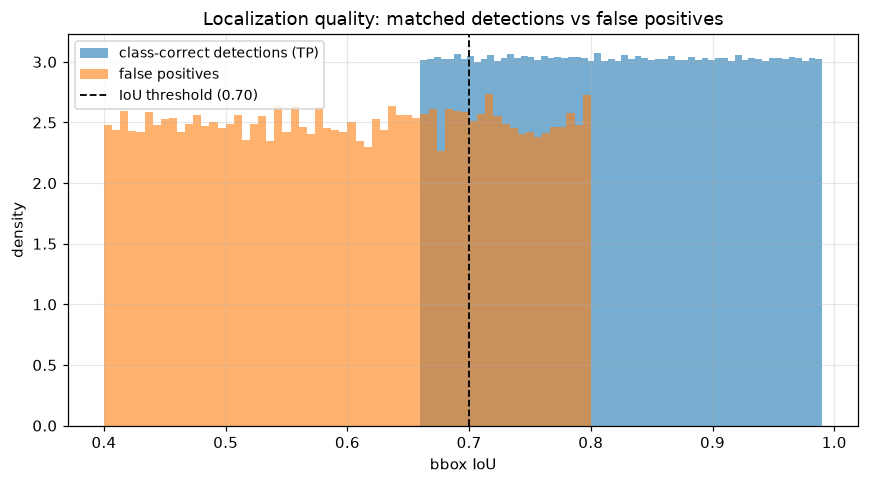

In [8]:
fig, ax = plt.subplots()
ax.hist(
    tps["bbox_iou"].to_numpy(),
    bins=60,
    alpha=0.6,
    density=True,
    label="class-correct detections (TP)",
)
ax.hist(
    df.filter(pl.col("is_false_positive") == 1)["bbox_iou"].to_numpy(),
    bins=60,
    alpha=0.6,
    density=True,
    label="false positives",
)
ax.axvline(0.7, color="black", linestyle="--", linewidth=1.2, label="IoU threshold (0.70)")
ax.set_xlabel("bbox IoU")
ax.set_ylabel("density")
ax.set_title("Localization quality: matched detections vs false positives")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_localization_quality.png")
plt.show()

## 5. Confidence threshold sweep

How do precision and recall trade off as we move the decision threshold?
Each point is the full 2.6M-sign dataset re-evaluated at a given threshold.

In [9]:
thresholds = np.round(np.arange(0.4, 0.951, 0.05), 3)
sweep_rows = []
for threshold in thresholds:
    effective = (
        pl.when(pl.col("confidence") >= threshold)
        .then(pl.col("predicted_class"))
        .otherwise(0)
    )
    tp_t, fp_t, fn_t = signs.select(
        (effective == pl.col("actual_class")).sum().alias("tp"),
        ((effective != 0) & (effective != pl.col("actual_class"))).sum().alias("fp"),
        (effective != pl.col("actual_class")).sum().alias("fn"),
    ).row(0)
    sweep_rows.append(
        {
            "threshold": float(threshold),
            "precision": tp_t / (tp_t + fp_t),
            "recall": tp_t / (tp_t + fn_t),
            "f1": 2 * tp_t / (2 * tp_t + fp_t + fn_t),
        }
    )

sweep = pl.DataFrame(sweep_rows)
sweep

threshold,precision,recall,f1
f64,f64,f64,f64
0.4,0.975335,0.952297,0.963679
0.45,0.978385,0.952297,0.965165
0.5,0.981393,0.952297,0.966626
0.55,0.984446,0.952297,0.968105
0.6,0.987551,0.952297,0.969604
…,…,…,…
0.75,0.99566,0.680226,0.808257
0.8,1.0,0.544422,0.705017
0.85,1.0,0.408244,0.579792


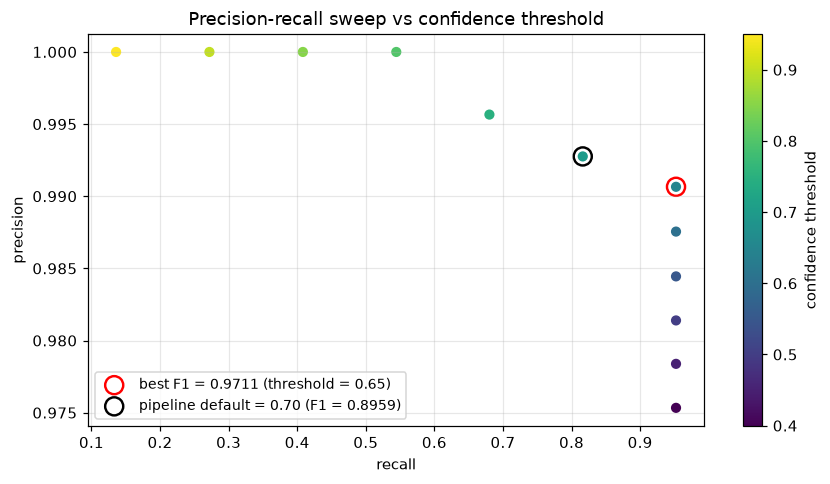

In [10]:
fig, ax = plt.subplots()
scatter = ax.scatter(sweep["recall"], sweep["precision"], c=sweep["threshold"], cmap="viridis", s=32)
fig.colorbar(scatter, ax=ax, label="confidence threshold")

best = sweep.sort("f1").tail(1)
ax.scatter(
    best["recall"],
    best["precision"],
    facecolors="none",
    edgecolors="red",
    s=140,
    linewidths=1.6,
    label=f"best F1 = {best['f1'][0]:.4f} (threshold = {best['threshold'][0]:.2f})",
)

current = sweep.filter((pl.col("threshold") - 0.7).abs() < 1e-9)
ax.scatter(
    current["recall"],
    current["precision"],
    facecolors="none",
    edgecolors="black",
    s=140,
    linewidths=1.6,
    label=f"pipeline default = 0.70 (F1 = {current['f1'][0]:.4f})",
)

ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-recall sweep vs confidence threshold")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_precision_recall_sweep.png")
plt.show()

## 6. Safety: critical failures

Reading the aggregated report straight from the BI layer
(`data/outputs/redash_db.sqlite`) produced by the `duckdb_bridge` asset.

In [11]:
import sqlite3

con = sqlite3.connect(ROOT / "data/outputs/redash_db.sqlite")
report = pl.read_database("SELECT * FROM kpi_report", con)
con.close()

report

weather_label,weather,total_frames,tp,tn,fp,fn,critical_failures,poor_localizations,avg_iou_tp,precision,recall,f1
str,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64
"""SUNNY""",0,3500259,1438861,1737771,24348,309686,0,174424,0.8249,0.9834,0.8229,0.896
"""RAIN""",1,999653,411303,495770,7109,88439,17448,49866,0.8249,0.983,0.823,0.8959
"""FOG""",2,500088,189197,248162,3473,60753,25163,23035,0.8251,0.982,0.7569,0.8549
"""ALL""",null,5000000,2039361,2481703,34930,458878,42611,247325,0.8249,0.9832,0.8163,0.892


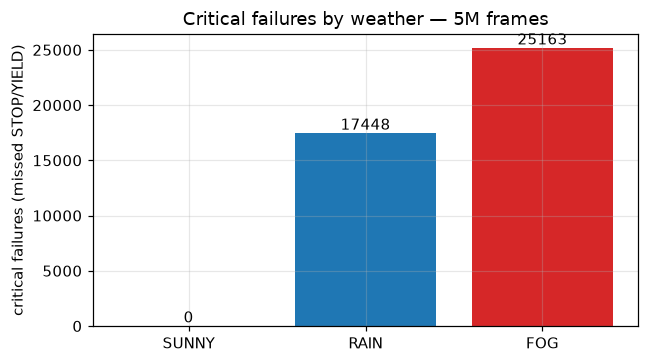

In [12]:
weather_rows = report.filter(pl.col("weather").is_not_null())

fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar(
    weather_rows["weather_label"].to_list(),
    weather_rows["critical_failures"].to_list(),
    color=["#2ca02c", "#1f77b4", "#d62728"],
)
ax.bar_label(bars, fmt="%d")
ax.set_ylabel("critical failures (missed STOP/YIELD)")
ax.set_title("Critical failures by weather — 5M frames")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_critical_failures.png")
plt.show()

## 7. Model A/B comparison

`scripts/compare_models.py` evaluates two model profiles with the exact same KPI
logic (v1 = baseline, v2 = improved: better fog handling, better calibrated
confidence and boxes) and writes `data/processed/model_comparison.parquet`:

```
uv run python scripts/compare_models.py
```

In [13]:
comparison = pl.read_parquet(ROOT / "data/processed/model_comparison.parquet")
comparison

model,weather,frames,tp,fp,fn,precision,recall,f1,critical_failures,poor_localizations
str,i64,u32,i32,i32,i32,f64,f64,f64,i32,i32
"""v1""",null,5000000,2039361,34930,458878,0.9832,0.8163,0.892,42611,247325
"""v1""",0,3500259,1438861,24348,309686,0.9834,0.8229,0.896,0,174424
"""v1""",1,999653,411303,7109,88439,0.983,0.823,0.8959,17448,49866
"""v1""",2,500088,189197,3473,60753,0.982,0.7569,0.8549,25163,23035
"""v2""",null,5000000,2433536,17484,65898,0.9929,0.9736,0.9832,9672,156406
"""v2""",0,3498515,1707302,12181,41883,0.9929,0.9761,0.9844,0,109814
"""v2""",1,1000082,487958,3568,12030,0.9927,0.9759,0.9843,2534,31346
"""v2""",2,501403,238276,1735,11985,0.9928,0.9521,0.972,7138,15246


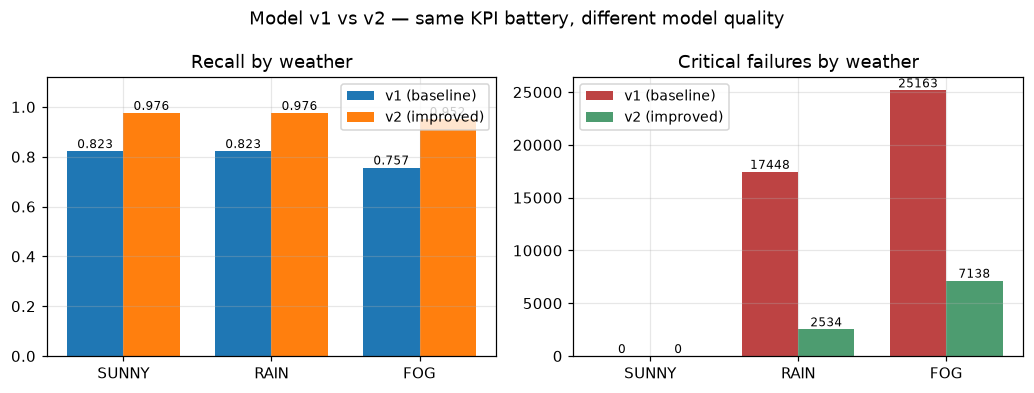

In [14]:
segments = comparison.filter(pl.col("weather").is_not_null()).sort(["weather", "model"])
labels = [WEATHER_NAMES[w] for w in segments["weather"].unique(maintain_order=True).to_list()]
v1 = segments.filter(pl.col("model") == "v1")
v2 = segments.filter(pl.col("model") == "v2")
x = np.arange(len(labels))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
bars = axes[0].bar(x - width / 2, v1["recall"], width, label="v1 (baseline)")
bars2 = axes[0].bar(x + width / 2, v2["recall"], width, label="v2 (improved)")
axes[0].bar_label(bars, fmt="%.3f", fontsize=8)
axes[0].bar_label(bars2, fmt="%.3f", fontsize=8)
axes[0].set_xticks(x, labels)
axes[0].set_ylim(0, 1.12)
axes[0].set_title("Recall by weather")
axes[0].legend(fontsize=9)

bars = axes[1].bar(x - width / 2, v1["critical_failures"], width, label="v1 (baseline)", color="firebrick", alpha=0.85)
bars2 = axes[1].bar(x + width / 2, v2["critical_failures"], width, label="v2 (improved)", color="seagreen", alpha=0.85)
axes[1].bar_label(bars, fontsize=8)
axes[1].bar_label(bars2, fontsize=8)
axes[1].set_xticks(x, labels)
axes[1].set_title("Critical failures by weather")
axes[1].legend(fontsize=9)

fig.suptitle("Model v1 vs v2 — same KPI battery, different model quality")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_model_comparison.png")
plt.show()

## 8. Confusion matrix & per-class metrics

Where do the errors actually go? Crossing *actual* class with the *effective*
prediction separates misses (`sign → NONE`), phantom detections (`NONE → sign`)
and genuine class confusions (`sign → other sign`).

In [15]:
df_effective = df.select(
    "actual_class",
    pl.when(pl.col("confidence") >= CONFIDENCE_THRESHOLD)
    .then(pl.col("predicted_class"))
    .otherwise(0)
    .alias("effective_class"),
)

CLASS_ORDER = (0, 1, 2, 3, 4)
confusion = (
    df_effective.group_by(["actual_class", "effective_class"])
    .len(name="frames")
    .pivot(on="effective_class", index="actual_class", values="frames")
    .fill_null(0)
    .sort("actual_class")
    .select("actual_class", *[str(c) for c in CLASS_ORDER])
)
confusion

actual_class,0,1,2,3,4
i64,u32,u32,u32,u32,u32
0,2481703,5078,4988,5002,4990
1,59033,189175,493,483,488
2,42579,483,205639,476,508
3,299789,3494,3533,1438903,3460
4,42605,479,482,493,205644


In [16]:
per_class_rows = []
for cls in (1, 2, 3, 4):
    is_actual = pl.col("actual_class") == cls
    is_predicted = pl.col("effective_class") == cls
    tp_c, fp_c, fn_c, support = df_effective.select(
        (is_actual & is_predicted).sum().alias("tp"),
        (~is_actual & is_predicted).sum().alias("fp"),
        (is_actual & ~is_predicted).sum().alias("fn"),
        is_actual.sum().alias("support"),
    ).row(0)
    per_class_rows.append(
        {
            "class": CLASS_NAMES[cls],
            "support": support,
            "precision": round(tp_c / (tp_c + fp_c), 4),
            "recall": round(tp_c / (tp_c + fn_c), 4),
            "f1": round(2 * tp_c / (2 * tp_c + fp_c + fn_c), 4),
            "missed": fn_c,
        }
    )
per_class = pl.DataFrame(per_class_rows)
per_class

class,support,precision,recall,f1,missed
str,i64,f64,f64,f64,i64
"""STOP""",249672,0.952,0.7577,0.8438,60497
"""YIELD""",249685,0.9559,0.8236,0.8848,44046
"""SPEED_LIMIT""",1749179,0.9955,0.8226,0.9009,310276
"""OTHER""",249703,0.9561,0.8236,0.8849,44059


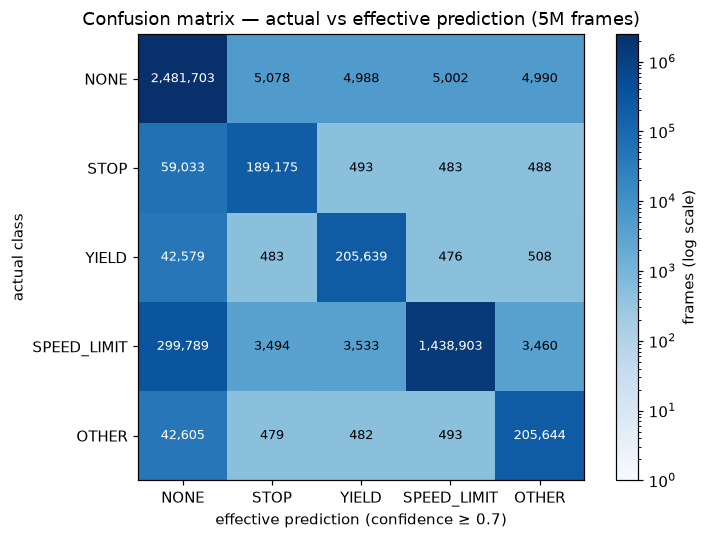

In [17]:
from matplotlib.colors import LogNorm

matrix = confusion.select([str(c) for c in CLASS_ORDER]).to_numpy()
labels = [CLASS_NAMES[c] for c in CLASS_ORDER]

fig, ax = plt.subplots(figsize=(6.8, 5))
norm = LogNorm(vmin=1, vmax=matrix.max())
image = ax.imshow(np.maximum(matrix, 1), cmap="Blues", norm=norm)
ax.set_xticks(range(len(labels)), labels)
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("effective prediction (confidence ≥ 0.7)")
ax.set_ylabel("actual class")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix[i, j]
        ax.text(
            j,
            i,
            f"{value:,}",
            ha="center",
            va="center",
            fontsize=8.5,
            color="white" if norm(max(value, 1)) > 0.6 else "black",
        )
ax.set_title("Confusion matrix — actual vs effective prediction (5M frames)")
fig.colorbar(image, ax=ax, label="frames (log scale)")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_confusion_matrix.png")
plt.show()

Reading the matrix:

- **Errors are misses, not confusions** — 444,006 signs collapse to `NONE` vs only
  14,872 sign→sign swaps (below 0.6% of all sign frames).
- Miss rate per class: **STOP 23.6%** (fog), all other classes a uniform ~17%
  (injected dropouts); the sign→sign cells are near-uniform synthetic noise.
- Empty frames generate 20,058 phantom detections, ~5k per class.

## 9. Key findings

- **Overall (5M frames): precision 0.9832, recall 0.8163, F1 0.892** — with the
  effective-prediction rule the pipeline is deliberately conservative.
- **Fog destroys STOP recall: 0.175 vs ~0.82 in sunny weather.** Other classes
  are basically weather-invariant (~0.82), matching the injected failure mode
  (80% of STOP signs missed in fog).
- **42,611 critical failures (missed STOP/YIELD in adverse weather), zero in
  sunny conditions** — every single one happens in rain or fog.
- **Localization: average IoU on matched detections is 0.825** and ~12% of
  matches fall below the 0.70 IoU threshold — a box-quality signal that is
  independent of weather in this benchmark.
- **Confusion matrix: 444k misses vs 14.9k sign→sign confusions (<0.6% of sign
  frames)** — errors are missed detections, not misclassifications; STOP miss
  rate is 23.6% (fog) vs a uniform ~17% for the other classes, plus 20k phantom
  detections on empty frames.
- **A/B: the improved v2 profile lifts overall recall 0.816 → 0.974 and cuts
  critical failures 42,611 → 9,672 (−77%)** at precision 0.993 — identical KPI
  logic, so model improvements are directly measurable.
- **The F1-optimal threshold for this synthetic model is 0.60 (F1 0.970)**, not
  the pipeline default 0.70 — the sweep turns the confidence threshold from a
  hidden constant into an explicit, measurable policy decision (a one-line change).
- Data is deterministic (generator `SEED=42`), so every number above is
  reproducible with `uv run python demo_run.py`.